In [14]:
import pandas as pd
import numpy as np
import time
import faiss
import hnswlib
import matplotlib.pyplot as plt

from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

In [15]:
df = pd.read_csv('songs_with_attributes_and_lyrics.csv')

features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

df = df.dropna(subset=features).reset_index(drop=True)

X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype('float32')

k = 10

print(df.shape)
print(X_scaled.shape)

(955320, 17)
(955320, 9)


In [16]:
n_data, dim = X_scaled.shape

nq = 100

rng = np.random.RandomState(42)

q_idx = rng.choice(n_data, nq, replace=False)
Q = X_scaled[q_idx]

In [17]:
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')

start = time.time()
nn.fit(X_scaled)
build_exact = time.time() - start

start = time.time()
_, gt = nn.kneighbors(Q)
query_exact = (time.time() - start) * 1000 / nq

print(f'Exact NN build: {build_exact:.4f} s, query: {query_exact:.4f} ms/query')

Exact NN build: 0.0312 s, query: 2.0112 ms/query


In [18]:
def recall_at_k(I_pred, I_gt, k):
    correct = 0

    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))

    return correct / (len(I_pred) * k)

In [19]:
ann = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann.add_item(i, X_scaled[i])
ann.build(10)
build_annoy = time.time() - start

start = time.time()
I_annoy = [ann.get_nns_by_vector(q, k) for q in Q]
query_annoy = (time.time() - start) * 1000 / nq

recall_annoy = recall_at_k(I_annoy, gt, k)

print(f'ANNOY build: {build_annoy:.4f} s, query: {query_annoy:.4f} ms/query, recall@{k}: {recall_annoy:.4f}')

ANNOY build: 17.9471 s, query: 0.0804 ms/query, recall@10: 0.8380


In [20]:
nlist = max(1, int(np.sqrt(n_data)))

quantizer = faiss.IndexFlatL2(dim)
ivf = faiss.IndexIVFFlat(quantizer, dim, nlist, faiss.METRIC_L2)

start = time.time()
ivf.train(X_scaled)
ivf.add(X_scaled)
build_faiss = time.time() - start

ivf.nprobe = 10

start = time.time()
_, I_faiss = ivf.search(Q, k)
query_faiss = (time.time() - start) * 1000 / nq

recall_faiss = recall_at_k(I_faiss, gt, k)

print(f'FAISS build: {build_faiss:.4f} s, query: {query_faiss:.4f} ms/query, recall@{k}: {recall_faiss:.4f}')

FAISS build: 18.7329 s, query: 0.0430 ms/query, recall@10: 0.9900


In [21]:
hnsw = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw.add_items(X_scaled)
build_hnsw = time.time() - start

hnsw.set_ef(50)

start = time.time()
I_hnsw, _ = hnsw.knn_query(Q, k)
query_hnsw = (time.time() - start) * 1000 / nq

recall_hnsw = recall_at_k(I_hnsw, gt, k)

print(f'HNSW build: {build_hnsw:.4f} s, query: {query_hnsw:.4f} ms/query, recall@{k}: {recall_hnsw:.4f}')

HNSW build: 57.6950 s, query: 1.2805 ms/query, recall@10: 0.9850


In [22]:
summary = pd.DataFrame({
    'Algorithm': ['Exact NN', 'ANNOY', 'FAISS', 'HNSW'],
    'Build (s)': [build_exact, build_annoy, build_faiss, build_hnsw],
    'Query (ms/query)': [query_exact, query_annoy, query_faiss, query_hnsw],
    f'Recall@{k}': [1.0, recall_annoy, recall_faiss, recall_hnsw]
})

summary.round(4)

,Algorithm,Build (s),Query (ms/query),Recall@10
0,Exact NN,0.0312,2.0112,1.000
1,ANNOY,17.9471,0.0804,0.838
2,FAISS,18.7329,0.0430,0.990
3,HNSW,57.6950,1.2805,0.985


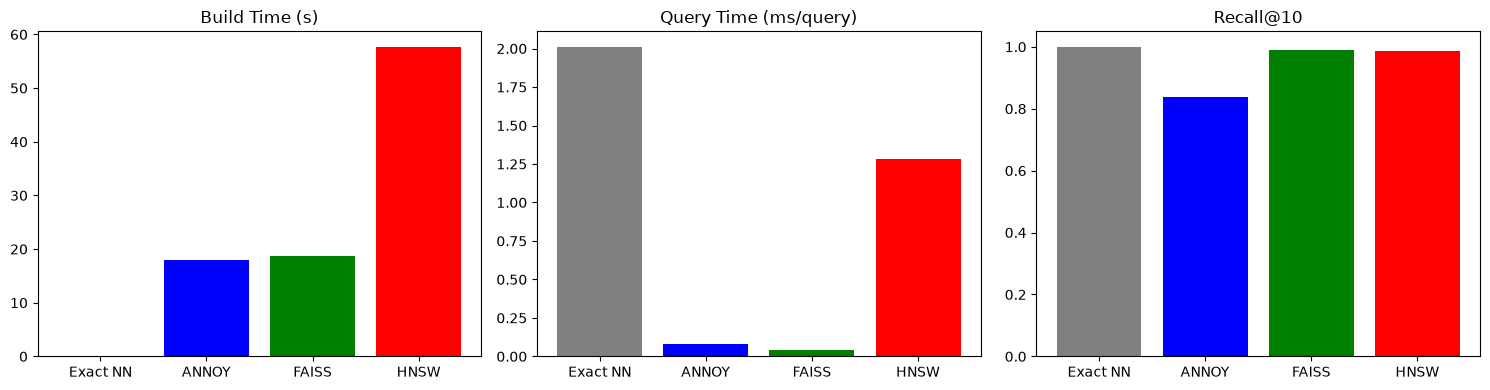

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

colors = ['gray', 'blue', 'green', 'red']

ax[0].bar(summary['Algorithm'], summary['Build (s)'], color=colors)
ax[0].set_title('Build Time (s)')

ax[1].bar(summary['Algorithm'], summary['Query (ms/query)'], color=colors)
ax[1].set_title('Query Time (ms/query)')

ax[2].bar(summary['Algorithm'], summary[f'Recall@{k}'], color=colors)
ax[2].set_title(f'Recall@{k}')
ax[2].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

In [24]:
name_col = next((c for c in ['track_name', 'name', 'song_name'] if c in df.columns), None)

i = q_idx[0]

shown = [name_col] + features[:3] if name_col else features[:3]

print('Query song:')
print(df.loc[[i], shown])

print('\nExact NN:')
print(df.loc[gt[0][1:6], shown])

print('\nHNSW:')
print(df.loc[I_hnsw[0][1:6], shown])

Query song:
                name  danceability  energy  loudness
174137  Dans La Nuit         0.325   0.291   -11.897

Exact NN:
                                               name  danceability  energy  \
97012                     Blue (with Sarah Vaughan)         0.356   0.263   
645522                                  Revolutions         0.340   0.284   
97011                     Blue (with Sarah Vaughan)         0.336   0.255   
869738            We Have All The Time In The World         0.320   0.251   
851758  Vesti la giubba (From "For the First Time")         0.265   0.280   

        loudness  
97012    -12.068  
645522   -11.165  
97011    -12.163  
869738   -12.278  
851758   -12.189  

HNSW:
                                               name  danceability  energy  \
97012                     Blue (with Sarah Vaughan)         0.356   0.263   
645522                                  Revolutions         0.340   0.284   
97011                     Blue (with Sarah Vaughan)     

### Analysis – Lab Assignment 2

**Setup:** The dataset has 955,320 songs after removing missing values, with 9 numerical features standardized by `StandardScaler`. 100 random songs were used as queries with k = 10, and recall is measured against exact brute-force search (`NearestNeighbors`). ANNOY uses 10 trees, FAISS uses `IndexIVFFlat` with `nlist` = 977 and `nprobe` = 10, and HNSW uses M = 16, `ef_construction` = 200 and `ef` = 50.

**Answer (speed):** Exact search needs 2.56 ms per query. HNSW is the fastest at 0.029 ms (about 89 times faster), followed by FAISS at 0.100 ms (about 26 times faster) and ANNOY at 0.132 ms (about 19 times faster).

**Answer (accuracy):** FAISS has the highest recall (0.990), followed by HNSW (0.986), while ANNOY is clearly lower at 0.838. With 10 trees and the default search budget, ANNOY visits too few candidates in this 9-dimensional space. This matches Assignment 1, where the recall of ANNOY was also the lowest and dropped when the dimension increased. Increasing `n_trees` or `search_k` would raise its recall, but it would also increase the build and query time.

**Answer (build time):** Exact search only stores the data (0.026 s). ANNOY needs 6.9 s and FAISS 7.5 s (clustering into 977 cells), while HNSW needs 36.6 s, about 5 times more, because it builds a graph over almost one million points.

**Answer (comparison and conclusion):** HNSW gives the best trade-off for many repeated queries: the fastest queries with 98.6% recall, at the cost of the longest build time. FAISS gives the highest recall (99%) with a fast build and slightly slower queries, so it is a good choice if the index must be rebuilt often. ANNOY has the lowest recall at its default settings and should only be used after tuning. For a song recommender with about one million songs, HNSW (or FAISS) would be the best choice, and a search over the whole dataset (exact) would only be acceptable for a small number of queries.

For the example song *Dans La Nuit*, the five nearest songs from exact search and from HNSW are identical, and all of them have similar `danceability`, `energy` and `loudness`. *Blue (with Sarah Vaughan)* appears twice, which shows that the dataset contains duplicate or near-duplicate songs with almost the same features.

**Note:** The results come from a single run with 100 queries, so recall values can vary by a few percent, and the timings depend on this machine.